# 02 Task 2: pipe length analysis
**Problem.** For every pipe $(u,v)$ compute its length $\ell(u,v)=\lVert p_u-p_v\rVert_2$ from the node coordinates; report the shortest, longest and total length; compare straight-line distance with shortest-path distance through the network; and store lengths so they can be queried efficiently.

**Input:** node coordinates and the pipe list. **Output:** one length per pipe, summary statistics, the network-to-straight-line distance ratio for all node pairs, and a queryable length index.

**Technique: geometric computation on a weighted graph, plus dynamic programming (Floyd-Warshall) for all-pairs network distances.** Length is a property of the pipe's geometry and is distinct from the third edge attribute (capacity, labelled as diameter in the challenge slides). These lengths are the edge weights of every shortest-path computation in tasks 3, 4 and 6.

In [1]:
import os, sys
if 'google.colab' in sys.modules and not os.path.isdir('../water'):
    os.system('git clone -q https://github.com/santihdzs/water-distribution')
    os.chdir('water-distribution/notebooks')
sys.path.insert(0, os.path.abspath('..'))

import bisect
import math
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import water
from water import graph, paths, plot, tasks, timing

plot.setup()
nets = water.load_all()

## Lengths
`Network.length` evaluates the Euclidean distance per pipe in $O(1)$, so all lengths cost $O(E)$. A vectorised NumPy version is computed as a cross-check (and timed in `08_performance`).

In [2]:
def lengths_vectorised(net):
    xy = np.array([[*net.coords[u], *net.coords[v]] for u, v, _ in net.pipes])
    return np.hypot(xy[:, 0] - xy[:, 2], xy[:, 1] - xy[:, 3])

L = {}
for name, net in nets.items():
    L[name] = {(u, v): net.length(u, v) for u, v, _ in net.pipes}
    assert np.allclose(list(L[name].values()), lengths_vectorised(net))

# lengths printed on the course's own figures of these networks (Water Graph Problem slides and instance images)
course_labels = {'FOS': {(4, 3): 2112.64, (3, 2): 817.15, (37, 1): 612.0, (7, 24): 1363.56},
                 'NYT': {(10, 17): 473.07, (18, 19): 309.65, (12, 18): 362.02},
                 'HAN': {(29, 28): 1398.45, (13, 12): 1683.19, (31, 30): 768.58}}
for name, labels in course_labels.items():
    for (u, v), ref in labels.items():
        assert abs(nets[name].length(u, v) - ref) < 0.01, (name, u, v)
print('all lengths match the values printed on the course figures to 0.01')

all lengths match the values printed on the course figures to 0.01


In [3]:
rows = []
for name, net in nets.items():
    lens = L[name]
    lo, hi = min(lens, key=lens.get), max(lens, key=lens.get)
    caps = [c for *_, c in net.pipes]
    rho = np.corrcoef(list(lens.values()), caps)[0, 1]
    total = sum(lens.values())
    rows.append([name, len(lens), total, f'{lo[0]}-{lo[1]}', lens[lo], f'{hi[0]}-{hi[1]}', lens[hi],
                 total / len(lens)])
    print(f'{name}: total {total:,.1f} | shortest {lo} {lens[lo]:.2f} | longest {hi} {lens[hi]:.2f} | '
          f'mean {total/len(lens):.1f} | corr(length, capacity) = {rho:+.2f}')

NYT: total 6,020.2 | shortest (9, 10) 182.21 | longest (9, 16) 480.84 | mean 286.7 | corr(length, capacity) = -0.65
HAN: total 33,827.4 | shortest (21, 22) 399.55 | longest (29, 30) 1780.86 | mean 994.9 | corr(length, capacity) = +0.13
FOS: total 56,154.2 | shortest (33, 34) 240.62 | longest (5, 6) 2284.79 | mean 968.2 | corr(length, capacity) = -0.30
PES: total 42,463.2 | shortest (26, 17) 3.57 | longest (9, 6) 1605.88 | mean 433.3 | corr(length, capacity) = -0.15


PES mixes very short pipes (shortest 3.57, pipe 26-17) with pipes up to 1606 units, a span of more than two orders of magnitude; the other instances span less than a factor of 10. Length and capacity are different attributes: their correlation ranges from 569JXgl0.65$ (NYT) to 1.13$ (HAN), so a long pipe is not necessarily a large one. Length drives distance (tasks 3, 4, 6), capacity drives flow (task 5).

 Geometric versus network distance
Water cannot travel in a straight line; it follows pipes. For every pair of nodes we compare the network distance $d_G(u,v)$ (all-pairs shortest paths by Floyd-Warshall, $O(V^3)$) with the straight-line distance $\lVert p_u-p_v\rVert$. The ratio $d_G/\lVert p_u-p_v\rVert\ge 1$ (circuity) measures how indirect the network is. A pipe is always the shortest route between its own endpoints because a straight segment cannot be beaten by a polyline (triangle inequality); this is checked as well.

In [4]:
circuity = {}
for name, net in nets.items():
    D, nxt, ids, index = tasks.metric_closure(net)
    G = nx.Graph()
    G.add_weighted_edges_from((u, v, net.length(u, v)) for u, v, _ in net.pipes)
    ref = dict(nx.all_pairs_dijkstra_path_length(G))
    assert all(abs(D[index[a], index[b]] - ref[a][b]) < 1e-6 for a in ids for b in ids)
    assert all(abs(D[index[u], index[v]] - L[name][(u, v)]) < 1e-9 for u, v, _ in net.pipes)
    iu = np.triu_indices(len(ids), 1)
    P = np.array([net.coords[u] for u in ids])
    E = np.hypot(*(P[:, None, :] - P[None, :, :]).transpose(2, 0, 1))
    r = D[iu] / E[iu]
    circuity[name] = r
    k = int(np.argmax(r))
    a, b = ids[iu[0][k]], ids[iu[1][k]]
    print(f'{name}: circuity mean {r.mean():.2f}, median {np.median(r):.2f}, max {r.max():.2f} '
          f'(nodes {a} and {b}: {E[iu][k]:.0f} apart, {D[iu][k]:.0f} by pipe)')
    rows[[x[0] for x in rows].index(name)] += [r.mean(), r.max()]

plot.table('lengths', rows,
           ['Inst.', '$|E|$', 'Total', 'Shortest', r'$\ell$', 'Longest', r'$\ell$', 'Mean', 'Circ. mean', 'Circ. max'],
           ['{}', '{}', '{:,.0f}', '{}', '{:.1f}', '{}', '{:.1f}', '{:.1f}', '{:.2f}', '{:.2f}'])

NYT: circuity mean 1.44, median 1.09, max 4.73 (nodes 3 and 14: 231 apart, 1095 by pipe)
HAN: circuity mean 1.32, median 1.32, max 3.32 (nodes 13 and 16: 1661 apart, 5518 by pipe)
FOS: circuity mean 1.19, median 1.21, max 1.75 (nodes 17 and 37: 869 apart, 1518 by pipe)
PES: circuity mean 1.83, median 1.31, max 28.20 (nodes 19 and 39: 147 apart, 4146 by pipe)


## Storing and querying lengths
Three ways to answer "how long is pipe $(u,v)$" and "which pipes are longer than $x$":

- **linear scan** of the pipe list: $O(E)$ per query, no extra memory (baseline);
- **hash index** keyed by the unordered pair: $O(1)$ expected per length query, $O(E)$ memory;
- **sorted array** of lengths: built once in $O(E\log E)$, then a threshold or range query costs $O(\log E + k)$ by binary search, where $k$ is the number of pipes reported.

The adjacency list of task 1 already stores the length next to each neighbour, so traversals never recompute it.

In [5]:
net = nets['PES']
index = {frozenset((u, v)): l for (u, v), l in L['PES'].items()}
order = sorted(L['PES'].items(), key=lambda kv: kv[1])
keys = [l for _, l in order]

def scan(u, v):
    for a, b, _ in net.pipes:
        if {a, b} == {u, v}:
            return net.length(a, b)

def longer_than(x):
    return [p for p, _ in order[bisect.bisect_right(keys, x):]]

u, v, _ = net.pipes[-1]
assert scan(u, v) == index[frozenset((u, v))]
assert set(longer_than(1000)) == {p for p, l in L['PES'].items() if l > 1000}
print(f'PES pipe {u}-{v}: {index[frozenset((u, v))]:.2f} | pipes longer than 1000: {len(longer_than(1000))} '
      f'found with {math.ceil(math.log2(len(keys) + 1))} comparisons instead of {len(keys)}')
print(f'median times: scan {timing.median_time(lambda: scan(u, v))*1e6:.2f} us, '
      f'hash {timing.median_time(lambda: index[frozenset((u, v))])*1e6:.3f} us')

PES pipe 55-86: 240.74 | pipes longer than 1000: 9 found with 7 comparisons instead of 98
median times: scan 6.72 us, hash 0.081 us


## Figure

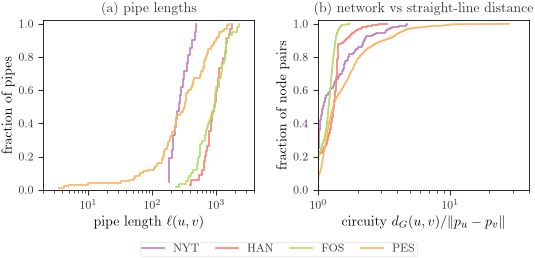

In [6]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(6.27, 2.2), gridspec_kw={'wspace': 0.3})
for k, (name, net) in enumerate(nets.items()):
    l = np.sort(list(L[name].values()))
    a1.step(l, np.arange(1, len(l) + 1) / len(l), where='post', color=plot.PALETTE[k], label=name)
    r = np.sort(circuity[name])
    a2.step(r, np.arange(1, len(r) + 1) / len(r), where='post', color=plot.PALETTE[k], label=name)
a1.set(xscale='log', xlabel=r'pipe length $\ell(u,v)$', ylabel='fraction of pipes', title='(a) pipe lengths')
a2.set(xscale='log', xlabel=r'circuity $d_G(u,v)/\lVert p_u-p_v\rVert$', ylabel='fraction of node pairs',
       title='(b) network vs straight-line distance')
for ax in (a1, a2):
    ax.set_ylim(0, 1.02)
a1.set_xlim(2, 4000)
a2.set_xlim(1, 40)
# both panels share the same four series, so one legend below the figure
fig.legend(*a1.get_legend_handles_labels(), loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=4)
plot.save(fig, 'lengths')
plt.show()

## Complexity
Lengths: $O(E)$ time and space. All-pairs network distances: $O(V^3)$ time and $O(V^2)$ space (Floyd-Warshall); the circuity table needs all $V(V-1)/2$ pairs. Queries as listed above.

## Interpretation
Total pipe length is the amount of infrastructure each utility maintains. Circuity shows how far each network is from straight-line supply. FOS, a regular mesh, keeps every pair within 1.75 times the straight-line distance. NYT and HAN are nearly trees, so some pairs that are close on the map are joined only around the tree (up to 4.7 times in NYT). PES is the extreme case: nodes 19 and 39 are 147 units apart but 4146 units apart by pipe (28 times), because PES consists of two dense clusters joined by very few pipes; task 3 finds that separating its sectors needs only two closures. A planner who estimated water travel by straight-line distance would underestimate it, which is why tasks 3 and 4 use network distance.